<a href="https://colab.research.google.com/github/ccwu0918/F0713-CPlusPlus/blob/main/C%2B%2B_Chapter16.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 班級: 資工一  學號: 13913001 姓名: 吳佳駿

In [ ]:
!pip install nvcc4jupyter

In [ ]:
%load_ext nvcc4jupyter

In [ ]:
!nvcc --version

#**Chapter 16: 類別的繼承**



#16.1 繼承的基本概念 (Page 16-2)



#16.1.1 基底類別與衍生類別: (Page 16-2 ~ 16-3)
*   以既有類別為基礎，進而衍生出另一類別，稱為「類別的繼承」

*   原有的類別稱為「父類別」或「基底類別」

*   因繼承而產生的新類別則稱為「子類別」或「衍生類別」

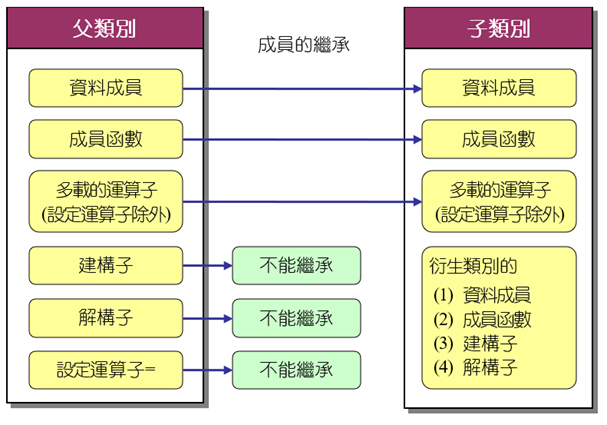

下面的範例是利用結構來表示視窗：

#16.1.2 簡單的繼承範例: prog16_1 (Page 16-3 ~ 12-5)

類別繼承的格式 ：

In [ ]:
%%cuda
// prog16_1, 繼承的簡單範例
#include <iostream>
#include <cstdlib>
using namespace std;
class CWin                          // 定義CWin類別，在此為父類別
{
   private:
     char id;
     int width,height;

   public:
     CWin(char i='D',int w=10,int h=10):id(i),width(w),height(h)
     {
        cout << "CWin()建構元被呼叫了..." << endl;
     }
     void show_member(void)  	    // 成員函數，用來顯示資料成員的值
     {
        cout << "Window " << id << ": ";
        cout << "width=" << width << ", height=" << height << endl;
     }
};

class CTextWin : public CWin        // 定義CTextWin類別，繼承自CWin類別
{
   private:                  	    // 子類別裡的私有成員
      char text[20];

   public:     					    // 子類別裡的公有成員
      CTextWin(char *tx)     		// 子類別的建構元
      {
         cout << "CTextWin()建構元被呼叫了..." << endl;
         strcpy(text,tx);
      }
      void show_text()			    // 子類別的成員函數
      {
         cout << "text = " << text << endl;
      }
};

int main(void)
{
   CWin win('A',50,60); 	   		// 建立父類別的物件
   CTextWin txt("Hello C++");		// 建立子類別的物件

   win.show_member();  			    // 以父類別物件呼叫父類別的函數
   txt.show_member();				// 以子類別物件呼叫父類別的函數
   txt.show_text();				    // 以子類別物件呼叫子類別的函數

   cout << "win 物件佔了 " << sizeof(win) << " bytes" << endl;
   cout << "txt 物件佔了 " << sizeof(txt) << " bytes" << endl;

   // system("pause");
   return 0;
}

本例的繼承關係圖：


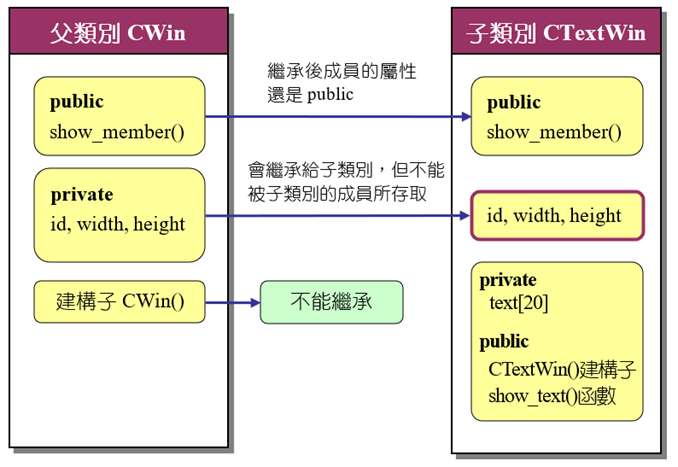

父類別與子類別所佔記憶體之比較：

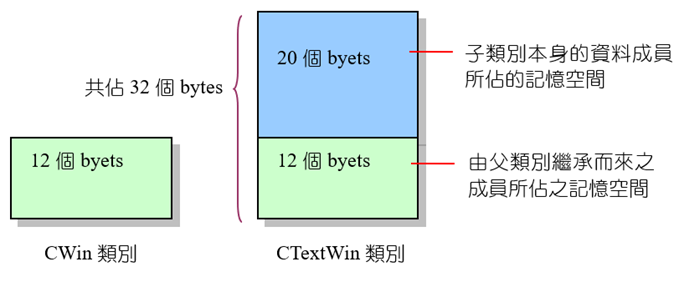

重要的觀念：
*  透過類別的繼承，可將父類別的成員繼承給子類別
*  在執行子類別的建構子之前，會先自動呼叫父類別中沒有引數的建構子
*  子類別物件所佔的位元組，等於自己資料成員所佔的位元組，加上繼承過來之成員所佔用的位元組


#16.1.3 呼叫父類別中特定的建構子: prog16_2 (Page 16-7 ~ 16-10)

呼叫父類別CWin裡特定建構子的範例：

重要的兩點：
* 若是省略27行的指定，會自動呼叫父類別無引數建構子
* 特定建構子的呼叫方式，必須寫在子類別建構子第一行的後面，使用「:父類別建構子(參數)」語法連接



In [ ]:
%%cuda
// prog16_2, 設定運算子多載的進階應用
#include <iostream>
#include <cstdlib>
using namespace std;
class CWin                              // 定義視窗類別CWin
{
   private:
     char id;
     int width,height;

   public:
     CWin(char i='D',int w=10,int h=10):id(i),width(w),height(h)
     {
        cout << "CWin()建構元被呼叫了..." << endl;
     }
     CWin(int w,int h):width(w),height(h)
     {
        cout << "CWin(int w,int h)建構元被呼叫了..." << endl;
        id='K';
     }
     void show_member(void)
     {
        cout << "Window " << id << ": ";
        cout << "width=" << width << ", height=" << height << endl;
     }
};

class CTextWin : public CWin
{
   private:
      char text[20];

   public:
      CTextWin(int w,int h): CWin(w,h)  // CTextWin(int,int)建構元
      {
         cout << "CTextWin(int w,int h)建構元被呼叫了..." << endl;
         strcpy(text,"Have a good night");
      }
      CTextWin(char *tx)                // CTextWin(char *)
      {
         cout << "CTextWin(char *tx)建構元被呼叫了..." << endl;
         strcpy(text,tx);
      }
      void show_text()
      {
         cout << "text = " << text << endl;
      }
};

int main(void)
{
   CTextWin tx1("Hello C++"); 	        // 呼叫39~43行的CTextWin()建構元
   CTextWin tx2(60,70);		            // 呼叫34~38行的CTextWin()建構元

   tx1.show_member();
   tx1.show_text();

   tx2.show_member();
   tx2.show_text();

   // system("pause");
   return 0;
}

#16.1.4 使用建構子常見的錯誤: prog16_3 (Page 16-10, 16-11)

呼叫父類別建構元時常犯的錯誤程式範例：

In [ ]:
%%cuda
// prog16_3, 呼叫父類別建構元時常犯的錯誤
#include <iostream>
#include <cstdlib>
using namespace std;
class CWin                                  // 定義視窗類別CWin
{
   private:
     char id;
     int width,height;

   public:
     CWin(int w,int h):width(w),height(h)   // 有兩個引數的建構元
     {
        cout << "CWin(int w,int h)建構元被呼叫了..." << endl;
        id='K';
     }
};

class CTextWin : public CWin                // 定義子類別CTextWin
{
   private:
      char text[20];

   public:
      CTextWin(char *tx)
      {
         cout << "CTextWin()建構元被呼叫了..." << endl;
         strcpy(text,tx);
      }
};

int main(void)
{
   CTextWin tx1("Hello C++");

   // system("pause");
   return 0;
}

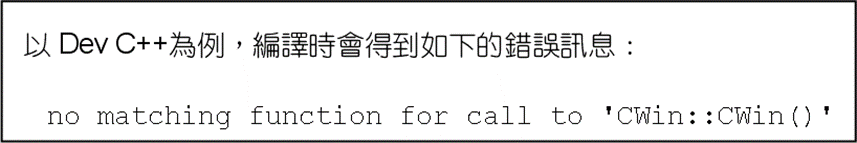

#16.1.4 使用建構子常見的錯誤: prog16_4 (Page 16-12)

修正呼叫父類別建構元時常犯的錯誤程式範例，prog16_3錯誤的修正：

In [ ]:
%%cuda
// prog16_4, prog16_3錯誤的修正
#include <iostream>
#include <cstdlib>
using namespace std;
class CWin                     // 定義視窗類別CWin
{
   private:
     char id;
     int width,height;

   public:
     CWin(int w,int h):width(w),height(h)
     {
        cout << "CWin(int w,int h)建構元被呼叫了..." << endl;
        id='K';
     }
     CWin()
     {
        cout<< "沒有引數的CWin()建構元被呼叫了..." << endl;
     }
};

class CTextWin : public CWin   // 定義子類別CTextWin
{
   private:
      char text[20];

   public:
      CTextWin(char *tx)
      {
         cout << "CTextWin()建構元被呼叫了..." << endl;
         strcpy(text,tx);
      }
};

int main(void)
{
   CTextWin tx1("Hello C++");

   // system("pause");
   return 0;
}

#16.2 由子類別存取父類別的成員

#16.2.1 父類別裡私有成員的存取: prog16_5 (Page 16-13)

呼叫父類別父類別裡私有成員常犯的錯誤程式範例，錯誤的例子-存取到父類別裡的私有成員：

In [ ]:
%%cuda
// prog16_5, 錯誤的例子--存取到父類別裡的私有成員
#include <iostream>
#include <cstdlib>
using namespace std;
class CWin                                  // 定義父類別CWin
{
   private:
     char id;

   public:
     CWin(char i):id(i) {}
};

class CTextWin : public CWin                // 定義子類別CTextWin
{
   private:
      char text[20];

   public:
      CTextWin(char i, char *tx):CWin(i)
      {
         strcpy(text,tx);
      }
      void show()
      {
         cout << "Window " << id << ": ";   // 讀取父類別裡的私有成員
         cout << "text = " << text << endl;
      }
};

int main(void)
{
   CTextWin txt('A',"Hello C++");

   txt.show();

   // system("pause");
   return 0;
}

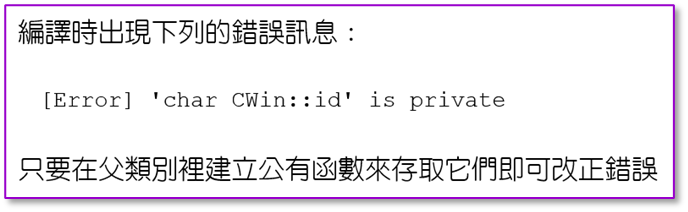

#16.2.1 父類別裡私有成員的存取: prog16_6 (Page 16-14)



修正呼叫父類別父類別裡私有成員常犯的錯誤程式範例，prog16_5的修正版：

In [ ]:
%%cuda
// prog16_6, prog16_5的修正版
#include <iostream>
#include <cstdlib>
using namespace std;
class CWin                      // 定義父類別CWin
{
   private:
     char id;

   public:
     CWin(char i):id(i) {}

     char get_id()		        // get_id()函數，用來取得id成員
     {
        return id;
     }
};

class CTextWin : public CWin    // 定義子類別CTextWin
{
   private:
      char text[20];

   public:
      CTextWin(char i,char *tx):CWin(i)
      {
         strcpy(text,tx);
      }
      void show()
      {
         cout << "Window " << get_id() << ": ";       // 呼叫父類別裡的get_id()
         cout << "text = " << text << endl;
      }
};

int main(void)
{
   CTextWin txt('A',"Hello C++");

   txt.show();

   // system("pause");
   return 0;
}

#16.2.2 使用protected成員: prog16_7 (Page 16-15, 16-16)

下面的範例是Ch16_5的小改版：


protected成員的最大好處是兼顧到成員的安全性與便利性

In [ ]:
%%cuda
// prog16_7, protected成員的使用
#include <iostream>
#include <cstdlib>
using namespace std;
class CWin          // 定義視窗類別CWin
{
   protected:
     char id;      // 把id宣告成protected成員，使得它也可以在子類別裡使用

   public:
     CWin(char i):id(i) {}
};

class CTextWin : public CWin
{
   private:
      char text[20];

   public:
      CTextWin(char i, char *tx):CWin(i)
      {
         strcpy(text,tx);
      }
      void show()
      {
         cout << "Window " << id << ": ";   // 讀取父類別裡的保護成員
         cout << "text = " << text << endl;
      }
};

int main(void)
{
   CTextWin txt('A',"Hello C++");

   txt.show();

   // system("pause");
   return 0;
}

#16.2.3 類別繼承的存取模式:

繼承的存取權限規則：

* Public 繼承
 1. 父類別的public成員 → 子類別的public成員
 2. 父類別的protected成員 → 子類別的protected 成員
* Protected 繼承
 1. 父類別的public和protected成員 → 子類別的protected成員
* Private 繼承
 1. 父類別的public和 protected成員 → 子類別的 private成員
* 特別注意
1. 父類別的private成員，子類別無法存取


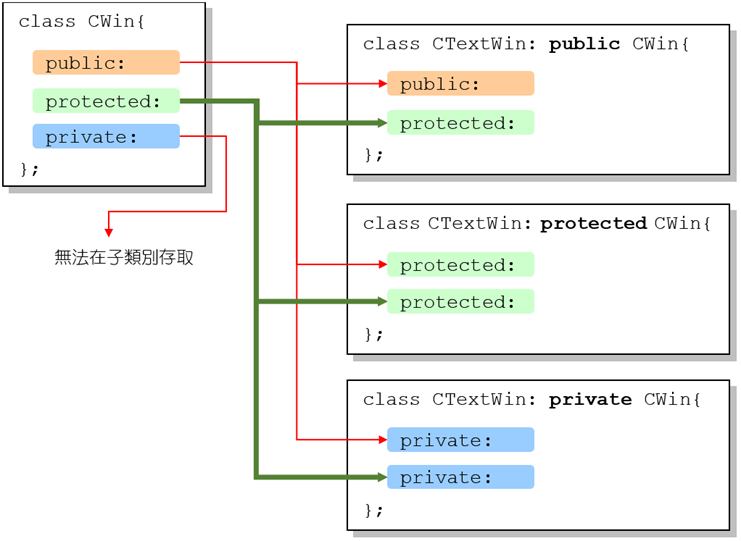

#16.3 改寫：prog16_8 (Page 16-18, 16-19)

* 「多載」是函數名稱相同，在不同的場合可做不同的事
* 「改寫」是在子類別裡定義與父類別名稱、引數相同的函數，用來覆蓋父類別裡函數功能的技術





簡單的改寫範例：


In [ ]:
%%cuda
// prog16_8, 繼承的簡單範例
#include <iostream>
#include <cstdlib>
using namespace std;
class CWin                                    // 定義CWin類別，在此為父類別
{
   protected:
     char id;

   public:
     CWin(char i):id(i){}

     void show_member(void)  	              // 父類別的show_member()函數
     {
        cout << "父類別的show_member()函數被呼叫了..." << endl;
        cout << "Window " << id << endl;
     }
};

class CTextWin : public CWin	              // 定義CTextWin類別，繼承自CWin類別
{
   private:                  	              // 子類別裡的私有成員
      char text[20];

   public:
      CTextWin(char i,char *tx):CWin('i')     // 子類別的建構元
      {
         strcpy(text,tx);
      }
      void show_member()                      // 子類別的show_member()函數
      {
         cout << "子類別的show_member()函數被呼叫了..." << endl;
         cout << "Window " << id << ": ";
         cout << "text = " << text << endl;
      }
};

int main(void)
{
   CTextWin txt('A',"Hello C++");		      // 建立子類別的物件

   txt.show_member();			              // 以子類別物件呼叫show_member()函數

   // system("pause");
   return 0;
}

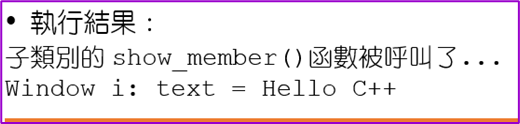

「改寫」與「多載」的比較
* 「多載」(overloading)：
在相同類別內，定義名稱相同，但引數個數或型態不同的函數，C++依據引數的個數或型態，呼叫相對應的函數
* 「改寫」(overriding)：
在子類別當中，定義名稱、引數個數與型態均與父類別相同的函數，用以改寫父類別裡函數的功用


# 16.4 在子類別中使用拷貝建構子：prog16_9 (Page 16-20 ~ 16-22)

下面是錯誤的使用拷貝建構子的範例：

如果父類別或子類別裡沒有提供拷貝建構子的話，編譯器會提供一個預設的拷貝建構子：

In [ ]:
%%cuda
// prog16_9, 錯誤的範例，子類別裡沒有撰寫拷貝建構元
#include <iostream>
#include <cstdlib>
using namespace std;
class CWin                                  // 定義CWin類別，在此為父類別
{
   protected:
     char id;

   public:
     CWin(char i='D'):id(i)   	            // 父類別的建構元
     {
        cout << "CWin()建構元被呼叫了..." << endl;
     }
     CWin(const CWin& win)    	            // 父類別的拷貝建構元
     {
        cout << "CWin()拷貝建構元被呼叫了..." << endl;
        id=win.id;
     }
     ~CWin()     				            // 父類別的解構元
     {
        cout << "CWin()解構元被呼叫了... " << endl;
        // system("pause");
     }
};

class CTextWin : public CWin                // 定義CTextWin類別，繼承自CWin類別
{
   private:                  	            // 子類別裡的私有成員
      char *text;

   public:
      CTextWin(char i,char *tx):CWin(i)     // 子類別的建構元
      {
         cout << "CTextWin()建構元被呼叫了..." << endl;
         text= new char[strlen(tx)+1];
         strcpy(text,tx);
      }
      ~CTextWin()
      {
         delete [] text;  			        // 釋放text指標所指向的記憶體
         cout << "CTextWin()解構元被呼叫了... " << endl;
         // system("pause");
      }
      void show_member()       		        // 子類別的show_member()函數
      {
         cout << "Window " << id << ": ";
         cout << "text = " << text << endl;
      }
      void set_member(char i,char *tx)      // 子類別的set_member()函數
      {
         id=i;
         delete [] text;               	    // 將原先指向的記憶體釋放
		text= new char[strlen(tx)+1];	    // 重新配置記憶體
         strcpy(text,tx);
      }
};
int main(void)
{
   CTextWin tx1('A',"Hello C++");	        // 建立子類別的物件tx1
   CTextWin tx2(tx1);				        // 以tx1建立子類別的物件tx2

   tx1.show_member();
   tx2.show_member();

   cout << "更改tx1物件的成員之後..." << endl;
   tx1.set_member('B',"Welcome  C++");

   tx1.show_member();
   tx2.show_member();

   // system("pause");
   return 0;
}

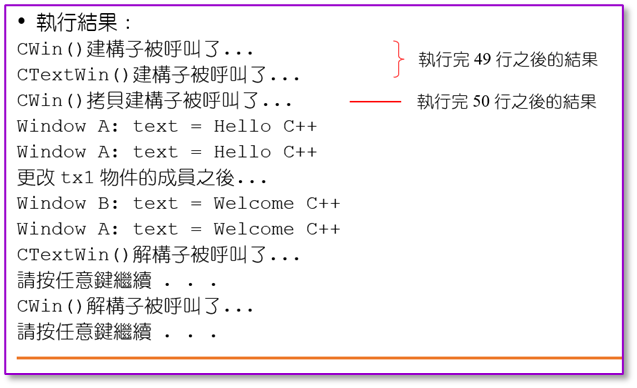

執行完49行後的結果：

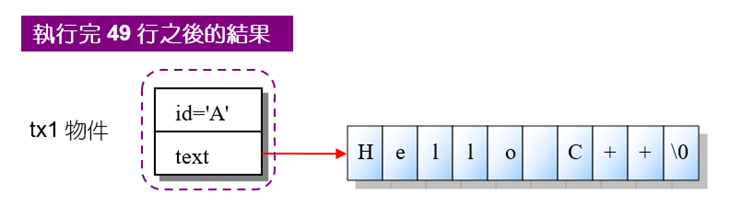

執行完50行後的結果：

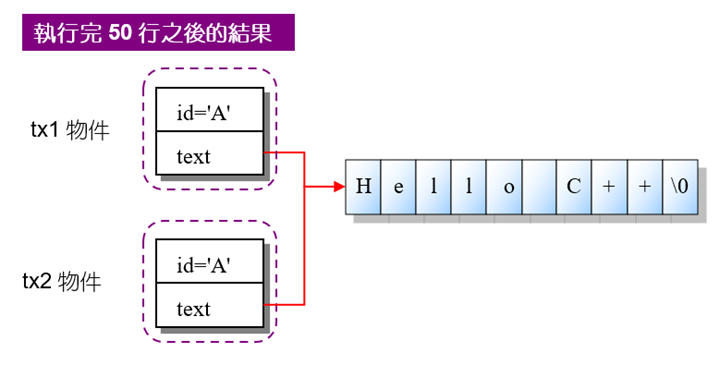

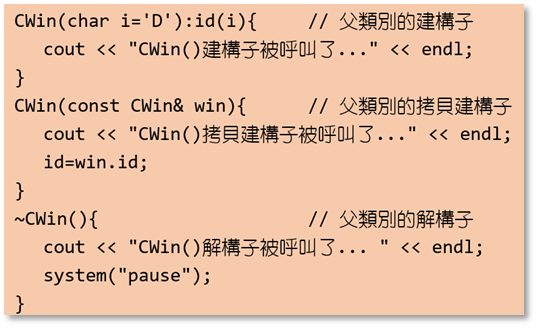

要解上面的錯誤，只要在子類別內加上一個拷貝建構子：

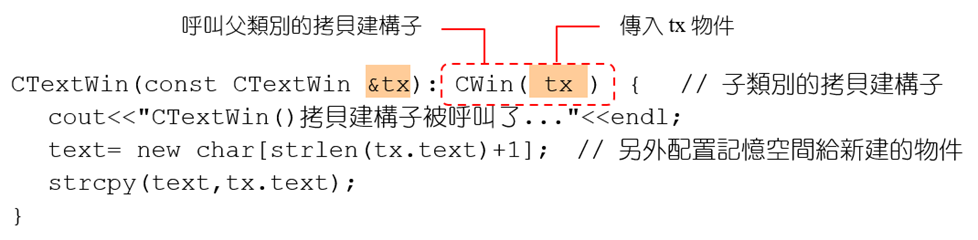

# 16.4 在子類別中使用拷貝建構子：prog16_10 (Page 16-24,16-25)

下面是修正沒有撰寫拷貝建構子的範例：




In [ ]:
%%cuda
// prog16_10, 修正prog16_9沒有撰寫拷貝建構元的錯誤
#include <iostream>
#include <cstdlib>
using namespace std;

class CWin                              // 定義CWin類別，在此為父類別
{
   protected:
     char id;

   public:
     CWin(char i='D'):id(i)   	        // 父類別的建構元
     {
        cout << "CWin()建構元被呼叫了..." << endl;
     }
     CWin(const CWin& win)    	        // 父類別的拷貝建構元
     {
        cout << "CWin()拷貝建構元被呼叫了..." << endl;
        id=win.id;
     }
     ~CWin()     				        // 父類別的解構元
     {
        cout << "CWin()解構元被呼叫了... " << endl;
        // system("pause");
     }
};

class CTextWin : public CWin            // 定義CTextWin類別，繼承自CWin類別
{
   private:                             // 子類別裡的私有成員
      char *text;

   public:
      CTextWin(char i,char *tx):CWin(i)     	// 子類別的建構元
      {
         cout << "CTextWin()建構元被呼叫了..." << endl;
         text= new char[strlen(tx)+1];
         strcpy(text,tx);
      }
      CTextWin(const CTextWin &tx):CWin(tx)	   // 子類別的拷貝建構元
      {
         cout << "CTextWin()拷貝建構元被呼叫了..." << endl;
         text= new char[strlen(tx.text)+1];
         strcpy(text,tx.text);
      }
      ~CTextWin()
      {
         delete [] text;  		        // 釋放text指標所指向的記憶體
         cout << "CTextWin()解構元被呼叫了... " << endl;
         // system("pause");
      }
      void show_member()                // 子類別的show_member()函數
      {
         cout << "Window " << id << ": ";
         cout << "text = " << text << endl;
      }
      void set_member(char i,char *tx)  // 子類別的set_member()函數
      {
         id=i;
		delete [] text;				    // 將原先指向的記憶體釋放
		text= new char[strlen(tx)+1];   // 重新配置記憶體
         strcpy(text,tx);
      }
};
int main(void)
{
   CTextWin tx1('A',"Hello C++");	    // 建立子類別的物件
   CTextWin tx2(tx1);

   tx1.show_member();
   tx2.show_member();

   cout << "更改tx1物件的成員之後..." << endl;
   tx1.set_member('B',"Welcome C++");

   tx1.show_member();
   tx2.show_member();

   // system("pause");
   return 0;
}

執行38與45行後之結果：

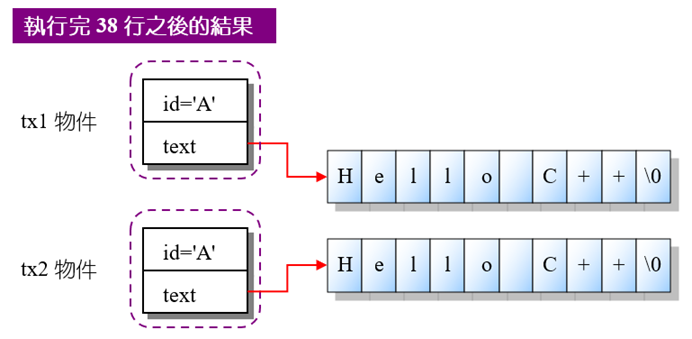

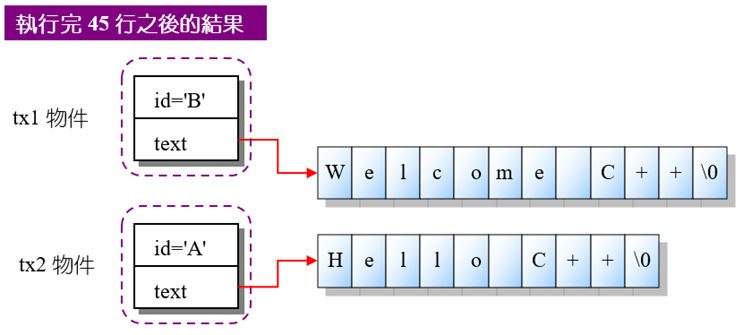

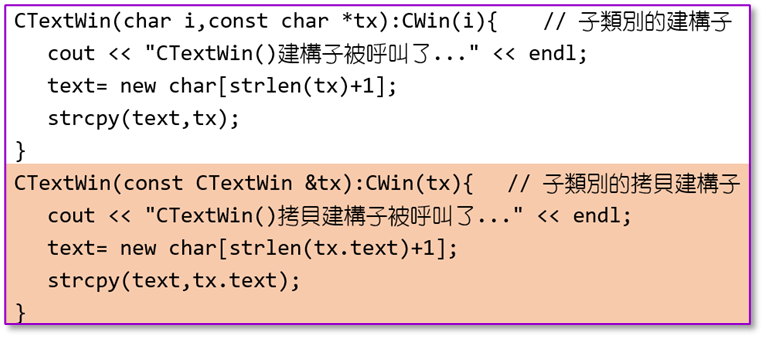

## 建構子與解構子的呼叫時機：

1. 建立物件時，父類別的建構子會先被執行，然後再執行子類別的建構子

2. 銷毀物件時，子類別的解構子會先被執行，然後再執行父類別的解構子





---



# 習題：16.1 繼承的基本概念   



### hw16_1.  C++在執行子類別的建構子之前，會先呼叫父類別中沒有引數的建構子，這麼做其目的是為什麼？：





In [ ]:
%%writefile hw16_1.cpp
// hw16_1, 班級: 資工一  學號: xxx 姓名: xxx
Ans:





### hw16_2.  如果父類別有數個建構子，我們要如何才能呼叫父類別中特定的建構子呢？




In [ ]:
%%writefile hw16_2.cpp
// hw16_2, 班級: 資工一  學號: xxx 姓名: xxx
Ans:





### hw16_3. 請試著逐步完成下列的程式設計：

請在main()中宣告出如左邊的程式，滿足(a)~（d)的要求並得到右的執行結果：


```
Animal animal;        animal, age: 1
Dog dog("Dog",3);      Dog, age: 3
Dog mydog;          puppy, age: 0
```




In [ ]:
%%writefile hw16_3.cpp
// hw16_3, 班級: 資工一  學號: xxx 姓名: xxx
#include <iostream>
#include <cstring>
using namespace std;
class Animal{		// 基底類別 Animal
	protected:


	public:




};

class Dog:public Animal {			// 子類別 Dog
	public:

};

int main(void){
	Animal animal;
   Dog dog("Dog",3);
	Dog mydog;

   animal.showInfo();
   dog.showInfo();
	 mydog.showInfo();
   return 0;
}

/* output-------------------------------
animal, age: 1
Dog, age: 3
puppy, age: 0
--------------------------------------*/

In [ ]:
!g++ hw16_3.cpp -o hw16_3

In [ ]:
!./hw16_3

# 習題：16.2 由子類別存取父類別的成員

### hw16_11. 於習題10中，在類別Cccc中是否可以直接存取到num的值？為什麼？


In [ ]:
%%writefile hw16_11.cpp
// hw16_11, 班級: 資工一  學號: xxx 姓名: xxx
Ans:






# 習題：16.3 改寫  



### hw14.  試比較「改寫」與「多載」的不同？


In [ ]:
%%writefile hw16_14.cpp
// hw16_14, 班級: 資工一  學號: xxx 姓名: xxx
Ans:






# 習題：16.4 在子類別中使用拷貝建構子  




### hw17.  在Ch16_10中，若不撰寫父類別的拷貝建構子，則程式執行時是否會有錯誤發生？為什麼？



In [ ]:
%%writefile hw16_17.cpp
// hw16_17, 班級: 資工一  學號: xxx 姓名: xxx
Ans:






#**Reference**
C++ Tutorial
https://www.w3schools.com/cpp/cpp_strings.asp

https://www.learn-cpp.org/en/Variables_and_Types

How to Run CUDA C or C++ on Jupyter (Google Colab)

https://www.wikihow.com/Run-CUDA-C-or-C%2B%2B-on-Jupyter-(Google-Colab)

Code block
http://www.codeblocks.org/downloads/26

Freebootcamp
https://www.freecodecamp.org/

ntroduction to C++ Programming in Urdu
https://www.youtube.com/watch?v=dnCO124Uk1o

6 Sentiment Analysis Projects with Python

https://amankharwal.medium.com/6-sentiment-analysis-projects-with-python-1fdd3d43d90f

C++ 教學講義

https://hackmd.io/@MECode/CPP